Clocked VAE - CERT r4.2 Pretraining Experiment

This notebook tests whether a public research dataset can improve the Clocked VAE.

The experiment compares:

1. Clocked-only VAE
2. CERT-pretrained VAE -> fine-tuned on Clocked

Both models are evaluated on the **same untouched Clocked test set**.


In [3]:
# libraries

import copy
import random
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

import torch
import torch.nn as nn
from torch.utils.data import DataLoader, TensorDataset

from sklearn.model_selection import train_test_split
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    roc_auc_score,
    average_precision_score,
    confusion_matrix,
    ConfusionMatrixDisplay,
)

SEED = 42

random.seed(SEED)
np.random.seed(SEED)
torch.manual_seed(SEED)

print("PyTorch:", torch.__version__)


PyTorch: 2.14.1


1. Load Clocked data

In [4]:
clocked_path = Path("unified_attendance_1250.csv")

if not clocked_path.exists():
    clocked_path = Path("/mnt/data/unified_attendance_1250.csv")

clocked = pd.read_csv(clocked_path)

clocked["clock_in_at"] = pd.to_datetime(
    clocked["clock_in_at"],
    errors="coerce",
)

clocked = clocked[
    clocked["fraud_label"].notna()
].copy()

clocked["fraud_label"] = (
    clocked["fraud_label"]
    .astype(int)
)

print("Clocked labelled rows:", len(clocked))
print(clocked["fraud_label"].value_counts())


Clocked labelled rows: 1000
fraud_label
0    820
1    180
Name: count, dtype: int64


Create a shared temporal feature space

The public CERT dataset and Clocked have different business fields.

To avoid pretending that unrelated variables are equivalent, both datasets are converted to the same six temporal features:

- hour sine
- hour cosine
- day-of-week sine
- day-of-week cosine
- duration scaled to a 24-hour day
- after-hours flag

The sine/cosine values handle the circular nature of clock time and weekdays.


In [5]:
TEMPORAL_FEATURES = [
    "hour_sin",
    "hour_cos",
    "day_sin",
    "day_cos",
    "duration_scaled",
    "after_hours",
]


def temporal_features(hour, day_of_week, duration_hours):
    hour = np.asarray(hour, dtype=float)
    day_of_week = np.asarray(day_of_week, dtype=float)
    duration_hours = np.asarray(duration_hours, dtype=float)

    hour_angle = 2 * np.pi * hour / 24.0
    day_angle = 2 * np.pi * day_of_week / 7.0

    after_hours = (
        (hour < 6.0) | (hour >= 18.0)
    ).astype(float)

    # keep very long values from dominating the VAE
    duration_scaled = (
        np.clip(duration_hours, 0, 24) / 24.0
    )

    return np.column_stack([
        np.sin(hour_angle),
        np.cos(hour_angle),
        np.sin(day_angle),
        np.cos(day_angle),
        duration_scaled,
        after_hours,
    ]).astype(np.float32)


In [6]:
# Clocked temporal features

clocked["start_hour"] = (
    clocked["clock_in_at"].dt.hour
    + clocked["clock_in_at"].dt.minute / 60.0
)

clocked["day_of_week"] = (
    clocked["clock_in_at"].dt.dayofweek
)

clocked = clocked.dropna(
    subset=[
        "start_hour",
        "day_of_week",
        "shift_hours",
    ]
).copy()

X_clocked = temporal_features(
    clocked["start_hour"],
    clocked["day_of_week"],
    clocked["shift_hours"],
)

y_clocked = (
    clocked["fraud_label"]
    .to_numpy(dtype=int)
)

print("Clocked temporal shape:", X_clocked.shape)


Clocked temporal shape: (1000, 6)


3. Load CERT r4.2 logon data

In [7]:
cert_logon_path = Path("logon.csv")
cert_insiders_path = Path("insiders.csv")

if not cert_logon_path.exists():
    raise FileNotFoundError(
        "Put CERT r4.2 logon.csv in the same folder as this notebook."
    )

if not cert_insiders_path.exists():
    raise FileNotFoundError(
        "Put CERT insiders.csv in the same folder as this notebook."
    )

cert_logon = pd.read_csv(
    cert_logon_path,
    low_memory=False,
)

cert_logon.columns = [
    str(column).strip().lower()
    for column in cert_logon.columns
]

print("CERT logon rows:", len(cert_logon))
print("Columns:", list(cert_logon.columns))
display(cert_logon.head())


CERT logon rows: 854859
Columns: ['id', 'date', 'user', 'pc', 'activity']


,id,date,user,pc,activity
0,{X1D9-S0ES98JV-5357PWMI},01/02/2010 06:49:00,NGF0157,PC-6056,Logon
1,{G2B3-L6EJ61GT-2222RKSO},01/02/2010 06:50:00,LRR0148,PC-4275,Logon
2,{U6Q3-U0WE70UA-3770UREL},01/02/2010 06:53:04,LRR0148,PC-4124,Logon
3,{I0N5-R7NA26TG-6263KNGM},01/02/2010 07:00:00,IRM0931,PC-7188,Logon
4,{D1S0-N6FH62BT-5398KANK},01/02/2010 07:00:00,MOH0273,PC-6699,Logon


4. Remove known CERT r4.2 insider users from pretraining

The VAE should learn normal behaviour.

The CERT answer key identifies known malicious users. For external pretraining, all r4.2 users listed in the insider answer key are removed completely.

This is deliberately conservative.


In [8]:
insiders = pd.read_csv(
    cert_insiders_path,
    low_memory=False,
)

insiders.columns = [
    str(column).strip().lower()
    for column in insiders.columns
]

if "dataset" in insiders.columns:
    dataset_number = pd.to_numeric(
        insiders["dataset"],
        errors="coerce",
    )

    insiders = insiders[
        np.isclose(dataset_number, 4.2)
    ].copy()

if "user" not in insiders.columns:
    raise ValueError(
        "Could not find the user column in insiders.csv"
    )

insider_users = set(
    insiders["user"]
    .astype(str)
    .str.strip()
)

print("CERT r4.2 insider users removed:", len(insider_users))


CERT r4.2 insider users removed: 70


5. Convert CERT logons into user-day work sessions

In [9]:
# find expected CERT columns

required = {"date", "user", "pc", "activity"}

missing = required - set(cert_logon.columns)

if missing:
    raise ValueError(
        f"CERT logon.csv is missing columns: {sorted(missing)}"
    )

cert_logon["datetime"] = pd.to_datetime(
    cert_logon["date"],
    errors="coerce",
)

cert_logon["user"] = (
    cert_logon["user"]
    .astype(str)
    .str.strip()
)

cert_logon["activity"] = (
    cert_logon["activity"]
    .astype(str)
    .str.strip()
    .str.lower()
)

cert_logon = cert_logon[
    ~cert_logon["user"].isin(insider_users)
].copy()

cert_logon = cert_logon.dropna(
    subset=["datetime"]
)

cert_logon = cert_logon.sort_values(
    ["user", "pc", "datetime"]
).reset_index(drop=True)

# pair each logon with the next logoff on the same user and PC
cert_logon["next_activity"] = (
    cert_logon
    .groupby(["user", "pc"])["activity"]
    .shift(-1)
)

cert_logon["next_datetime"] = (
    cert_logon
    .groupby(["user", "pc"])["datetime"]
    .shift(-1)
)

session_mask = (
    cert_logon["activity"].eq("logon")
    & cert_logon["next_activity"].eq("logoff")
)

sessions = cert_logon[
    session_mask
].copy()

sessions["duration_hours"] = (
    (
        sessions["next_datetime"]
        - sessions["datetime"]
    )
    .dt.total_seconds()
    / 3600.0
)

sessions = sessions[
    sessions["duration_hours"].between(
        0,
        24,
        inclusive="both",
    )
].copy()

sessions["day"] = (
    sessions["datetime"].dt.normalize()
)

sessions["start_hour"] = (
    sessions["datetime"].dt.hour
    + sessions["datetime"].dt.minute / 60.0
)

daily = (
    sessions
    .groupby(["user", "day"], as_index=False)
    .agg(
        start_hour=("start_hour", "min"),
        duration_hours=("duration_hours", "sum"),
    )
)

daily["day_of_week"] = (
    pd.to_datetime(daily["day"])
    .dt.dayofweek
)

print("CERT normal user-days:", len(daily))
display(daily.head())


CERT normal user-days: 314828


,user,day,start_hour,duration_hours,day_of_week
0,AAE0190,2010-01-04,8.150000,10.183333,0
1,AAE0190,2010-01-05,8.316667,9.866667,1
2,AAE0190,2010-01-06,8.150000,10.016667,2
3,AAE0190,2010-01-07,8.383333,9.850000,3
4,AAE0190,2010-01-08,8.283333,10.150000,4


In [10]:
X_cert = temporal_features(
    daily["start_hour"],
    daily["day_of_week"],
    daily["duration_hours"],
)

# keep laptop runtime reasonable
MAX_CERT_ROWS = 50000

if len(X_cert) > MAX_CERT_ROWS:
    rng = np.random.default_rng(SEED)
    selected = rng.choice(
        len(X_cert),
        size=MAX_CERT_ROWS,
        replace=False,
    )
    X_cert = X_cert[selected]

print("CERT rows used for pretraining:", len(X_cert))
print("CERT feature shape:", X_cert.shape)


CERT rows used for pretraining: 50000
CERT feature shape: (50000, 6)


6. Keep one Clocked test set for both experiments

In [11]:
indices = np.arange(len(X_clocked))

train_index, test_index = train_test_split(
    indices,
    test_size=0.30,
    random_state=SEED,
    stratify=y_clocked,
)

X_clocked_train = X_clocked[train_index]
y_clocked_train = y_clocked[train_index]

X_clocked_test = X_clocked[test_index]
y_clocked_test = y_clocked[test_index]

X_clocked_normal = X_clocked_train[
    y_clocked_train == 0
]

print("Clocked normal training rows:", len(X_clocked_normal))
print("Clocked test rows:", len(X_clocked_test))
print(
    "Clocked test fraud rows:",
    int(y_clocked_test.sum()),
)


Clocked normal training rows: 574
Clocked test rows: 300
Clocked test fraud rows: 54


7. VAE

In [12]:
class VAE(nn.Module):
    def __init__(
        self,
        input_dim=6,
        hidden_dim=32,
        latent_dim=8,
    ):
        super().__init__()

        self.encoder = nn.Sequential(
            nn.Linear(input_dim, hidden_dim),
            nn.ReLU(),
        )

        self.mu = nn.Linear(
            hidden_dim,
            latent_dim,
        )

        self.logvar = nn.Linear(
            hidden_dim,
            latent_dim,
        )

        self.decoder = nn.Sequential(
            nn.Linear(latent_dim, hidden_dim),
            nn.ReLU(),
            nn.Linear(hidden_dim, input_dim),
        )

    def encode(self, x):
        hidden = self.encoder(x)
        return self.mu(hidden), self.logvar(hidden)

    def reparameterize(self, mu, logvar):
        std = torch.exp(0.5 * logvar)
        noise = torch.randn_like(std)
        return mu + noise * std

    def forward(self, x):
        mu, logvar = self.encode(x)
        z = self.reparameterize(mu, logvar)
        reconstructed = self.decoder(z)

        return reconstructed, mu, logvar


def vae_loss(
    reconstructed,
    original,
    mu,
    logvar,
):
    reconstruction = nn.functional.mse_loss(
        reconstructed,
        original,
        reduction="mean",
    )

    kl = -0.5 * torch.mean(
        1
        + logvar
        - mu.pow(2)
        - logvar.exp()
    )

    return reconstruction + 0.001 * kl


In [13]:
device = torch.device(
    "cuda"
    if torch.cuda.is_available()
    else "cpu"
)

print("Using:", device)


def train_model(
    model,
    data,
    epochs,
    learning_rate=0.001,
    batch_size=64,
):
    model = model.to(device)

    tensor = torch.tensor(
        data,
        dtype=torch.float32,
    )

    loader = DataLoader(
        TensorDataset(tensor),
        batch_size=batch_size,
        shuffle=True,
    )

    optimizer = torch.optim.Adam(
        model.parameters(),
        lr=learning_rate,
    )

    history = []

    for epoch in range(epochs):
        model.train()
        total_loss = 0.0

        for (batch,) in loader:
            batch = batch.to(device)

            optimizer.zero_grad()

            reconstructed, mu, logvar = model(
                batch
            )

            loss = vae_loss(
                reconstructed,
                batch,
                mu,
                logvar,
            )

            loss.backward()
            optimizer.step()

            total_loss += (
                loss.item() * len(batch)
            )

        history.append(
            total_loss / len(loader.dataset)
        )

    return model, history


def reconstruction_error(
    model,
    data,
):
    model.eval()

    tensor = torch.tensor(
        data,
        dtype=torch.float32,
        device=device,
    )

    with torch.no_grad():
        mu, _ = model.encode(tensor)
        reconstructed = model.decoder(mu)

        error = torch.mean(
            (tensor - reconstructed) ** 2,
            dim=1,
        )

    return error.cpu().numpy()


def evaluate_model(
    name,
    model,
    normal_training_data,
    test_data,
    test_labels,
):
    train_error = reconstruction_error(
        model,
        normal_training_data,
    )

    threshold = float(
        np.percentile(
            train_error,
            95,
        )
    )

    test_error = reconstruction_error(
        model,
        test_data,
    )

    prediction = (
        test_error > threshold
    ).astype(int)

    return {
        "Model": name,
        "Accuracy": accuracy_score(
            test_labels,
            prediction,
        ),
        "Precision": precision_score(
            test_labels,
            prediction,
            zero_division=0,
        ),
        "Recall": recall_score(
            test_labels,
            prediction,
            zero_division=0,
        ),
        "F1 Score": f1_score(
            test_labels,
            prediction,
            zero_division=0,
        ),
        "ROC AUC": roc_auc_score(
            test_labels,
            test_error,
        ),
        "PR AUC": average_precision_score(
            test_labels,
            test_error,
        ),
        "threshold": threshold,
        "prediction": prediction,
        "score": test_error,
    }


Using: cpu


8. Experiment A - Clocked only

In [14]:
torch.manual_seed(SEED)

baseline_model = VAE()

baseline_model, baseline_history = train_model(
    baseline_model,
    X_clocked_normal,
    epochs=80,
    learning_rate=0.001,
    batch_size=32,
)

baseline_result = evaluate_model(
    "Clocked only",
    baseline_model,
    X_clocked_normal,
    X_clocked_test,
    y_clocked_test,
)

print(
    "Clocked-only F1:",
    round(
        baseline_result["F1 Score"],
        4,
    ),
)


Clocked-only F1: 0.3373


9. Experiment B - CERT pretraining then Clocked fine-tuning

In [15]:
torch.manual_seed(SEED)

pretrained_model = VAE()

# learn broad temporal behaviour from CERT first
pretrained_model, cert_history = train_model(
    pretrained_model,
    X_cert,
    epochs=40,
    learning_rate=0.001,
    batch_size=256,
)

# then adapt the same VAE to normal Clocked attendance
pretrained_model, finetune_history = train_model(
    pretrained_model,
    X_clocked_normal,
    epochs=60,
    learning_rate=0.0005,
    batch_size=32,
)

pretrained_result = evaluate_model(
    "CERT pretrained + Clocked",
    pretrained_model,
    X_clocked_normal,
    X_clocked_test,
    y_clocked_test,
)

print(
    "CERT-pretrained F1:",
    round(
        pretrained_result["F1 Score"],
        4,
    ),
)


CERT-pretrained F1: 0.3256


10. Compare results

In [16]:
comparison = pd.DataFrame([
    {
        key: value
        for key, value in baseline_result.items()
        if key not in {
            "prediction",
            "score",
            "threshold",
        }
    },
    {
        key: value
        for key, value in pretrained_result.items()
        if key not in {
            "prediction",
            "score",
            "threshold",
        }
    },
]).set_index("Model")

display(comparison.round(4))

winner = comparison["F1 Score"].idxmax()

print()
print(
    f"Better model based on Clocked test F1: {winner}"
)


,Accuracy,Precision,Recall,F1 Score,ROC AUC,PR AUC
Model,,,,,,
Clocked only,0.8167,0.4828,0.2593,0.3373,0.5978,0.3908
CERT pretrained + Clocked,0.8067,0.4375,0.2593,0.3256,0.5892,0.3912



Better model based on Clocked test F1: Clocked only


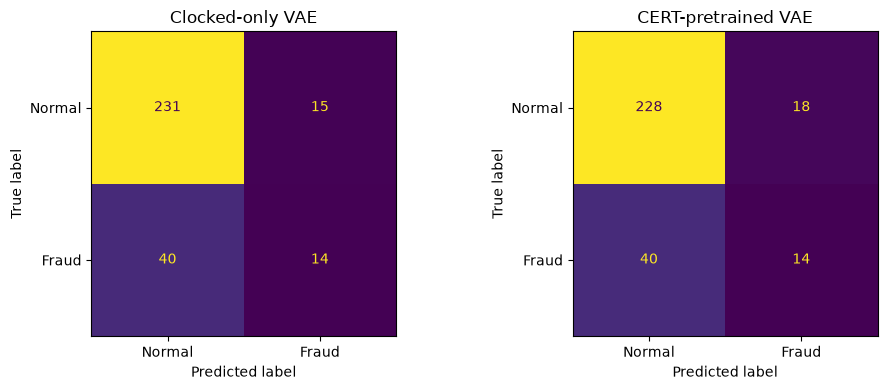

In [17]:
fig, axes = plt.subplots(
    1,
    2,
    figsize=(10, 4),
)

ConfusionMatrixDisplay(
    confusion_matrix(
        y_clocked_test,
        baseline_result["prediction"],
    ),
    display_labels=[
        "Normal",
        "Fraud",
    ],
).plot(
    ax=axes[0],
    colorbar=False,
)

axes[0].set_title(
    "Clocked-only VAE"
)

ConfusionMatrixDisplay(
    confusion_matrix(
        y_clocked_test,
        pretrained_result["prediction"],
    ),
    display_labels=[
        "Normal",
        "Fraud",
    ],
).plot(
    ax=axes[1],
    colorbar=False,
)

axes[1].set_title(
    "CERT-pretrained VAE"
)

plt.tight_layout()
plt.show()
